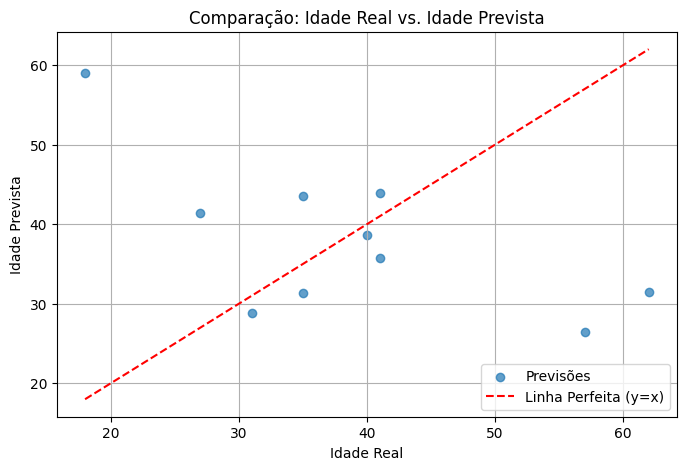

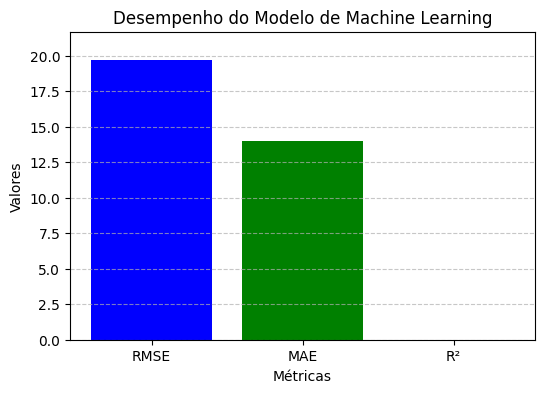

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. GERANDO DADOS FICTÍCIOS LOCALMENTE
def gerar_dados():
    """Gera um dataset fictício simulando a API."""
    np.random.seed(42)
    nomes = ["Alice", "Bob", "Carlos", "Diana", "Eduardo", "Fernanda", "Gabriel", "Helena", "Igor", "Julia"]
    cidades = ["São Paulo", "Rio de Janeiro", "Belo Horizonte", "Curitiba", "Recife"]
    paises = ["Brasil", "Argentina", "Chile", "México", "EUA"]

    data = {
        "nome": np.random.choice(nomes, 50),
        "idade": np.random.randint(18, 70, 50),
        "genero": np.random.choice(["Masculino", "Feminino"], 50),
        "cidade": np.random.choice(cidades, 50),
        "pais": np.random.choice(paises, 50)
    }

    return pd.DataFrame(data)

# 2. ARMAZENAMENTO - SQLite
DB_PATH = "dados_pipeline.db"
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

cursor.execute("""
    CREATE TABLE IF NOT EXISTS usuarios (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome TEXT,
        idade INTEGER,
        genero TEXT,
        cidade TEXT,
        pais TEXT
    )
""")
conn.commit()

df = gerar_dados()
df.to_sql("usuarios", conn, if_exists="replace", index=False)

# 3. PRÉ-PROCESSAMENTO DOS DADOS
def preprocessar_dados():
    """Carrega os dados do banco e aplica pré-processamento."""
    conn = sqlite3.connect(DB_PATH)
    df = pd.read_sql("SELECT * FROM usuarios", conn)
    conn.close()

    # Remover colunas irrelevantes
    df = df.drop(columns=['id', 'nome'], errors='ignore')

    # Converter variáveis categóricas para números
    df['genero'] = df['genero'].astype('category').cat.codes
    df['cidade'] = df['cidade'].astype('category').cat.codes
    df['pais'] = df['pais'].astype('category').cat.codes

    return df

df = preprocessar_dados()
df.to_csv("dados_transformados.csv", index=False)

# 4. TREINAMENTO DE MODELO MACHINE LEARNING
def treinar_modelo():
    """Treina um modelo de Machine Learning e salva o resultado."""
    df = pd.read_csv("dados_transformados.csv")
    X = df.drop(columns=['idade'])
    y = df['idade']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    modelo = RandomForestRegressor(n_estimators=100, random_state=42)
    modelo.fit(X_train, y_train)

    y_pred = modelo.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    joblib.dump(modelo, "modelo_random_forest.pkl")

    return pd.DataFrame({
        "Idade Real": y_test,
        "Idade Prevista": y_pred
    }), rmse, mae, r2

# Treinar o modelo e obter os resultados
resultados_df, rmse, mae, r2 = treinar_modelo()

# 5. PLOTAR RESULTADOS COM MATPLOTLIB

# Criar gráfico de dispersão para comparar Idade Real vs. Idade Prevista
plt.figure(figsize=(8, 5))
plt.scatter(resultados_df["Idade Real"], resultados_df["Idade Prevista"], alpha=0.7, label="Previsões")
plt.plot([resultados_df["Idade Real"].min(), resultados_df["Idade Real"].max()],
         [resultados_df["Idade Real"].min(), resultados_df["Idade Real"].max()],
         'r--', label="Linha Perfeita (y=x)")

# Configuração do gráfico
plt.xlabel("Idade Real")
plt.ylabel("Idade Prevista")
plt.title("Comparação: Idade Real vs. Idade Prevista")
plt.legend()
plt.grid(True)

# Exibir o gráfico
plt.show()

# Criar gráfico de barras para mostrar métricas do modelo
metricas = ["RMSE", "MAE", "R²"]
valores = [rmse, mae, r2]

plt.figure(figsize=(6, 4))
plt.bar(metricas, valores, color=['blue', 'green', 'orange'])

# Configuração do gráfico
plt.xlabel("Métricas")
plt.ylabel("Valores")
plt.title("Desempenho do Modelo de Machine Learning")
plt.ylim(0, max(valores) + 2)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Exibir o gráfico
plt.show()
